# Two-view geometry: the epipolar constraint, the essential matrix and triangulation

Two calibrated views of a static scene are the smallest unit of 3D vision: stereo cameras,
visual odometry, SfM and SLAM all build on it. This notebook derives the two-view relations
from a synthetic scene whose ground truth we control, then tests the same estimators on
real images with motion-capture ground truth (TUM RGB-D `fr1_desk`).

**What you will learn**

* the epipolar constraint $\hat{x}_2^\top E\,\hat{x}_1 = 0$ with $E = [t]_\times R$, and the
  fundamental matrix $F = K_2^{-\top} E K_1^{-1}$ for pixel coordinates;
* the (Hartley-normalised) 8-point algorithm written from scratch, why normalisation
  matters, and why the 5-point algorithm inside RANSAC is the workhorse on real data;
* how an essential matrix decomposes into four poses and how the **cheirality check**
  (points must be in front of both cameras) selects the right one (`cv2.recoverPose`);
* linear (DLT) triangulation, reprojection error, and how depth uncertainty grows as the
  baseline shrinks, the reason robot stereo rigs and VO systems care about parallax.

**Prerequisites:** pinhole projection and rigid transforms (project 01, `cvlab.geometry`),
SVD. **Runtime:** about 1 minute on CPU; no GPU is needed.

## Setup

Project-specific helpers (8-point, E decomposition, matching, metrics) live in
`projects/09_multiview_geometry/scripts/mvgeo.py` so that they are unit-tested
(`tests/test_p09_mvgeo.py`) and shared by all four notebooks.

In [1]:
# --- Setup: imports, seeding, repo-relative paths, plotting style ---
# cvlab provides the camera/pose maths; mvgeo adds the two-view estimators of this project.
import sys
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import cvlab.device
from cvlab import geometry as G
from cvlab import viz
from cvlab.io import data_dir, project_dir, save_json
from cvlab.tum import load_sequence

PROJECT = "09_multiview_geometry"
sys.path.insert(0, str(project_dir(PROJECT) / "scripts"))
import mvgeo as M  # noqa: E402

device = cvlab.device.setup(seed=0)
viz.set_style()
RESULTS_DIR = project_dir(PROJECT) / "results"
rng = np.random.default_rng(0)

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)


## 1. A synthetic two-view scene

We place 400 random 3D points in a 2 m box and two cameras that look at it, using
`cvlab.geometry.look_at` (OpenCV camera axes: x right, y down, z forward). Each camera has
the intrinsics $K$ of a 640x480 sensor with a 60° horizontal field of view.

Projection of a world point $X_w$ into camera $i$ with world-to-camera extrinsics
$T_{c_i w} = [R_i\,|\,t_i]$:

$$\lambda\,x_i = K\,(R_i X_w + t_i), \qquad x_i = (u, v, 1)^\top .$$

The **relative pose** maps camera-1 coordinates into camera-2 coordinates,
$X_2 = R X_1 + t$, with $T_{21} = T_{c_2 w}\,T_{w c_1}$.

400 of 400 points visible in both views
baseline |C2 - C1| = 1.428 m, relative rotation = 25.7 deg


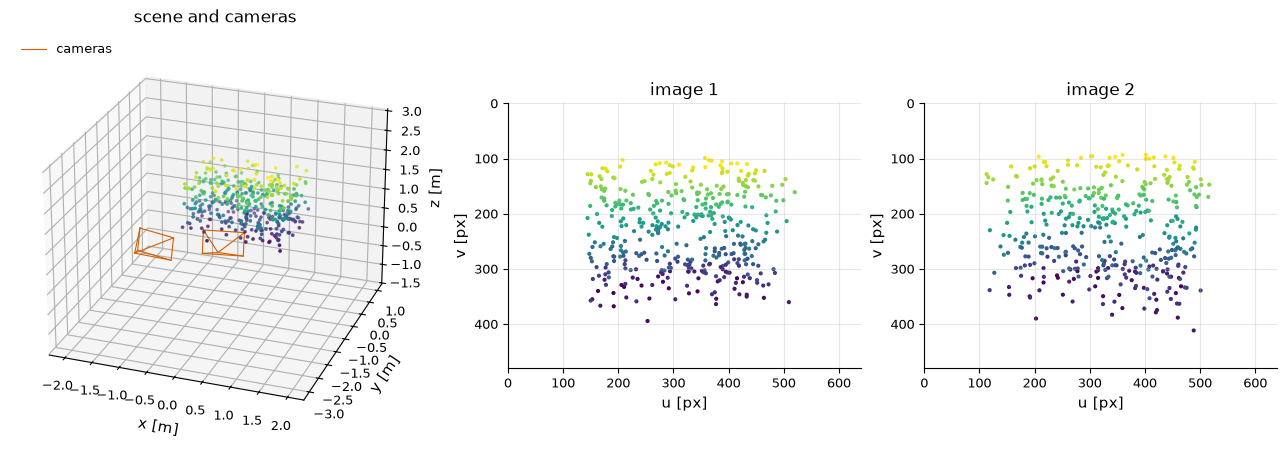

In [2]:
# --- Build the scene, the cameras and the ground-truth correspondences ---
# World frame: z up. Points live in a box; both cameras look at its centre.
W, H = 640, 480
cam = G.PinholeCamera.from_fov(W, H, fov_x_deg=60.0)
K = cam.K
X_world = rng.uniform([-1.0, -0.5, 0.0], [1.0, 1.0, 1.5], size=(400, 3))  # metres

T_wc1 = G.look_at(eye=[-0.8, -3.0, 1.2], target=[0.0, 0.2, 0.7])  # camera-to-world poses
T_wc2 = G.look_at(eye=[0.6, -2.8, 1.4], target=[0.0, 0.2, 0.7])
R_gt, t_gt = M.relative_pose_from_c2w(T_wc1, T_wc2)  # x2 = R x1 + t (metres)

uv1, z1 = G.project_points(X_world, K, G.invert_T(T_wc1))
uv2, z2 = G.project_points(X_world, K, G.invert_T(T_wc2))
vis = (z1 > 0) & (z2 > 0) & cam.in_image(uv1) & cam.in_image(uv2)
x1_all, x2_all, X_vis = uv1[vis], uv2[vis], X_world[vis]
print(f"{vis.sum()} of {len(X_world)} points visible in both views")
print(f"baseline |C2 - C1| = {np.linalg.norm(T_wc2[:3, 3] - T_wc1[:3, 3]):.3f} m, "
      f"relative rotation = {np.rad2deg(np.linalg.norm(G.so3_log(R_gt))):.1f} deg")

fig = plt.figure(figsize=(13, 4.4))
gs = fig.add_gridspec(1, 3, width_ratios=[1.3, 1, 1])
ax = fig.add_subplot(gs[0], projection="3d")
ax.scatter(*X_vis.T, s=3, c=X_vis[:, 2], cmap="viridis")
viz.plot_camera_frustums(ax, np.stack([T_wc1, T_wc2]), K, W, H, scale=0.6,
                         color_rgb=viz.color(5, unit=True), label="cameras")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_zlabel("z [m]")
ax.view_init(elev=25, azim=-70)
viz.set_axes_equal(ax)
ax.set_title("scene and cameras")
ax.legend(loc="upper left")
for k, (uv, name) in enumerate([(x1_all, "image 1"), (x2_all, "image 2")]):
    a = fig.add_subplot(gs[k + 1])
    a.scatter(uv[:, 0], uv[:, 1], s=4, c=X_vis[:, 2], cmap="viridis")
    a.set_xlim(0, W)
    a.set_ylim(H, 0)
    a.set_aspect("equal")
    a.set_xlabel("u [px]")
    a.set_ylabel("v [px]")
    a.set_title(name)
plt.show()

## 2. The epipolar constraint, $E$ and $F$

Camera 2's centre, the 3D point and its two projections lie in one plane (the
*epipolar plane*). Written in camera-2 coordinates, the vectors $t$ and $R X_1$ span that
plane, so $X_2 = RX_1 + t$ is orthogonal to their cross product:

$$X_2^\top\,[t]_\times R\,X_1 = 0 \;\;\Longrightarrow\;\; \hat{x}_2^\top E\,\hat{x}_1 = 0,
\qquad E = [t]_\times R,$$

where $\hat{x} = K^{-1}x$ are normalised image coordinates. For pixels,
$x_2^\top F x_1 = 0$ with $F = K_2^{-\top} E K_1^{-1}$.

* $E$ has 5 degrees of freedom (3 rotation + 2 for the direction of $t$: **scale is lost**);
  its singular values are $(\sigma, \sigma, 0)$.
* $F$ has 7 degrees of freedom and rank 2. $l_2 = F x_1$ is the **epipolar line** of
  $x_1$ in image 2; all epipolar lines meet at the **epipole** $e_2$ (the image of camera
  1's centre), with $F e_1 = 0$ and $F^\top e_2 = 0$.

In [3]:
# --- Verify the constraint numerically and locate the epipoles ---
# cvlab.geometry builds E and F; the residual x2^T F x1 should be ~0 for noise-free data.
E_gt = G.essential_from_Rt(R_gt, t_gt)
F_gt = G.fundamental_from_essential(E_gt, K, K)
res = M.algebraic_residual(F_gt, x1_all, x2_all)
d_epi = M.point_line_distance(M.to_h(x1_all) @ F_gt.T, x2_all)  # px, point 2 to line F x1
chk = M.essential_check(E_gt)
print(f"max |x2^T F x1| = {np.abs(res).max():.2e}, max point-to-epipolar-line distance "
      f"= {d_epi.max():.2e} px")
print("singular values of E (normalised):", np.round(chk["singular_values"], 6),
      f"| cubic constraint residual {chk['cubic_residual']:.1e}")

# Epipoles = null vectors of F, compared with the projections of the other camera centre.
_, _, Vt = np.linalg.svd(F_gt)
e1 = Vt[-1] / Vt[-1][2]
_, _, Vt = np.linalg.svd(F_gt.T)
e2 = Vt[-1] / Vt[-1][2]
c2_in_1, _ = G.project_points(T_wc2[:3, 3][None], K, G.invert_T(T_wc1))
c1_in_2, _ = G.project_points(T_wc1[:3, 3][None], K, G.invert_T(T_wc2))
print(f"epipole e1 = {e1[:2].round(2)} px  vs camera-2 centre projected into image 1 = "
      f"{c2_in_1[0].round(2)}")
print(f"epipole e2 = {e2[:2].round(2)} px  vs camera-1 centre projected into image 2 = "
      f"{c1_in_2[0].round(2)}")

max |x2^T F x1| = 7.22e-15, max point-to-epipolar-line distance = 1.63e-13 px
singular values of E (normalised): [1. 1. 0.] | cubic constraint residual 2.1e-15
epipole e1 = [1778.38  -69.84] px  vs camera-2 centre projected into image 1 = [1778.38  -69.84]
epipole e2 = [-6144.35  1051.88] px  vs camera-1 centre projected into image 2 = [-6144.35  1051.88]


The epipoles lie far outside the 640x480 images because the cameras look roughly in the
same direction: the epipolar lines are nearly parallel. In a rectified stereo rig
(notebook 02) the epipoles are at infinity and every epipolar line is an image row.

Below, each colour is one correspondence: its point in image 1 (left) and the epipolar
line $l_2 = F x_1$ on which its partner must lie in image 2 (right), and vice versa.

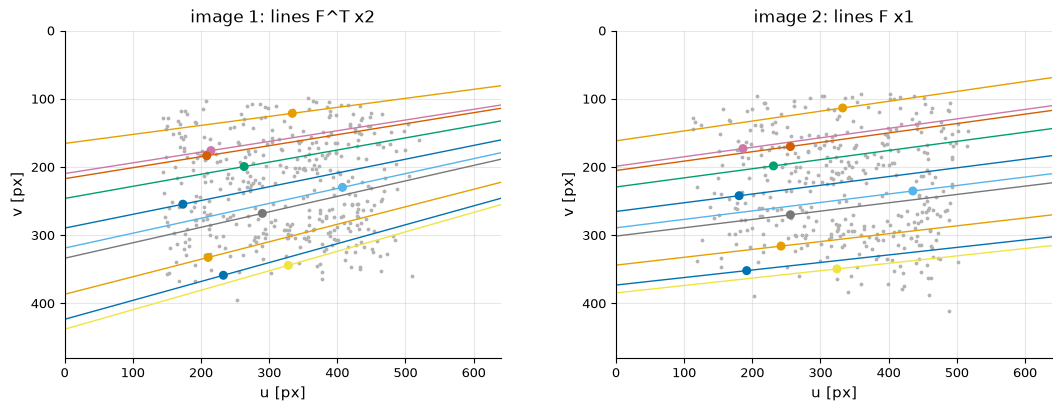

In [4]:
# --- Draw epipolar lines in both images ---
# Lines l = (a, b, c) satisfy a*u + b*v + c = 0; we clip them to the image width.
def draw_lines(ax, lines, colors, width):
    for (a, b, c), col in zip(lines, colors):
        us = np.array([0.0, width])
        ax.plot(us, -(a * us + c) / b, color=col, lw=1)

sel = rng.choice(len(x1_all), 10, replace=False)
cols = [viz.color(i, unit=True) for i in range(len(sel))]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
lines2 = M.to_h(x1_all[sel]) @ F_gt.T  # l2 = F x1
lines1 = M.to_h(x2_all[sel]) @ F_gt  # l1 = F^T x2
for ax, pts, lines, title in [(axes[0], x1_all, lines1, "image 1: lines F^T x2"),
                              (axes[1], x2_all, lines2, "image 2: lines F x1")]:
    ax.scatter(pts[:, 0], pts[:, 1], s=3, color="0.7")
    ax.scatter(pts[sel, 0], pts[sel, 1], s=30, c=cols, zorder=3)
    draw_lines(ax, lines, cols, W)
    ax.set_xlim(0, W)
    ax.set_ylim(H, 0)
    ax.set_aspect("equal")
    ax.set_xlabel("u [px]")
    ax.set_ylabel("v [px]")
    ax.set_title(title)
plt.show()

## 3. Estimating $F$ and $E$ from correspondences

**8-point algorithm.** Each correspondence gives one linear equation in the nine entries of
$F$: $[u_2u_1,\,u_2v_1,\,u_2,\,v_2u_1,\,v_2v_1,\,v_2,\,u_1,\,v_1,\,1]\cdot f = 0$. Stacking
$N\ge 8$ rows gives $A f = 0$; the least-squares solution is the right singular vector of
$A$ with the smallest singular value. The result is then projected to rank 2.

**Hartley normalisation.** With raw pixels the columns of $A$ range from $\sim 1$ to
$\sim 10^5$, so $A$ is badly conditioned and noise is amplified. Translating the points to
their centroid and scaling them to a mean distance of $\sqrt{2}$ (matrices $T_1, T_2$),
solving, and undoing it with $F = T_2^\top \tilde{F} T_1$ fixes this.

**5-point algorithm** (Nistér 2004). With known $K$, $E$ has only 5 DoF, so 5
correspondences suffice (up to 10 real solutions). The minimal sample matters inside
**RANSAC**: the chance that a random sample is outlier-free is $(1-\varepsilon)^s$ for
outlier ratio $\varepsilon$ and sample size $s$, so 5-point samples need far fewer
iterations than 8-point samples.

We compare six estimators over 50 random trials per setting: our 8-point on raw pixels,
our Hartley-normalised 8-point, OpenCV's `FM_8POINT`, 8-point inside classic RANSAC
(`FM_RANSAC`), and the 5-point solver inside classic RANSAC (`cv2.RANSAC`) and inside
MAGSAC++ (`cv2.USAC_MAGSAC`, which adds local optimisation and a final fit on all inliers). Every $F$ is
converted to $E = K^\top F K$ and decomposed with `cv2.recoverPose`. Errors are the rotation
angle error and the angle between the estimated and true translation directions.

In [5]:
# --- Noise sweep: Gaussian pixel noise on 100 correspondences, no outliers ---
# Same random samples for all methods (seeded); median errors over 50 trials.
def sample(n, sigma, outlier_frac, rng):
    idx = rng.choice(len(x1_all), n, replace=False)
    a = x1_all[idx] + rng.normal(0, sigma, (n, 2))
    b = x2_all[idx] + rng.normal(0, sigma, (n, 2))
    n_out = int(round(outlier_frac * n))
    b[:n_out] = rng.uniform([0, 0], [W, H], (n_out, 2))  # gross mismatches
    return a, b

def pose_from_F(F, a, b, mask=None):
    if F is None or F.shape != (3, 3):
        return None
    E = M.essential_from_fundamental(F, K, K)
    _, R, t, _ = cv2.recoverPose(E, a, b, K, mask=None if mask is None else mask.copy())
    return R, t.ravel()

def five_point(a, b, thr, method=cv2.RANSAC):
    E, mask = cv2.findEssentialMat(a, b, K, method, 0.999, thr)
    if E is None or E.shape != (3, 3):
        return None
    _, R, t, _ = cv2.recoverPose(E, a, b, K, mask=mask.copy())
    return R, t.ravel()

def f_ransac(a, b, thr):
    F, mask = cv2.findFundamentalMat(a, b, cv2.FM_RANSAC, thr, 0.999)
    return pose_from_F(F, a, b, mask)

METHODS = {
    "8-pt raw pixels": lambda a, b, thr: pose_from_F(M.eight_point(a, b, normalize=False), a, b),
    "8-pt normalised": lambda a, b, thr: pose_from_F(M.eight_point(a, b), a, b),
    "OpenCV FM_8POINT": lambda a, b, thr: pose_from_F(cv2.findFundamentalMat(a, b, cv2.FM_8POINT)[0], a, b),
    "8-pt + RANSAC": f_ransac,
    "5-pt + RANSAC": five_point,
    "5-pt + MAGSAC++": lambda a, b, thr: five_point(a, b, thr, cv2.USAC_MAGSAC),
}

def run_trials(sigma, outlier_frac, methods, n=100, trials=50, seed=0):
    rng_t = np.random.default_rng(seed)
    errs = {m: [] for m in methods}
    for _ in range(trials):
        a, b = sample(n, sigma, outlier_frac, rng_t)
        thr = max(1.0, 3.0 * sigma)  # RANSAC inlier threshold [px]
        for name in methods:
            out = METHODS[name](a, b, thr)
            errs[name].append((180.0, 180.0) if out is None else M.pose_errors(*out, R_gt, t_gt))
    return {m: np.median(np.array(v), axis=0) for m, v in errs.items()}

SIGMAS = [0.1, 0.5, 1.0, 2.0, 4.0]
t0 = time.perf_counter()
noise_rows = []
for s in SIGMAS:
    for name, (er, et) in run_trials(s, 0.0, list(METHODS)).items():
        noise_rows.append({"sigma_px": s, "method": name, "rot_err_deg": er, "t_err_deg": et})
noise_df = pd.DataFrame(noise_rows)
print(f"noise sweep: {time.perf_counter() - t0:.1f} s")
noise_df.pivot(index="method", columns="sigma_px", values="rot_err_deg").round(3)

noise sweep: 0.7 s


sigma_px,0.1,0.5,1.0,2.0,4.0
method,,,,,
5-pt + MAGSAC++,0.057,0.241,0.673,2.366,9.724
5-pt + RANSAC,0.558,1.220,2.560,5.188,9.878
8-pt + RANSAC,0.511,1.506,2.909,5.350,11.381
8-pt normalised,0.065,0.327,0.664,1.363,2.688
8-pt raw pixels,0.096,1.453,5.563,18.088,32.080
OpenCV FM_8POINT,0.065,0.327,0.664,1.363,2.688


Two lessons from the table (median rotation error in degrees):

* **Normalisation is essential.** The raw-pixel 8-point estimate degrades much faster with
  noise than the normalised one; our normalised implementation reproduces OpenCV's
  `FM_8POINT` (which normalises internally) to the printed precision.
* **Classic RANSAC returns the model of the best *minimal sample*.** Without outliers it
  is several times less accurate than a least-squares fit on all points, because 5 or 8
  noisy points determine the model. MAGSAC++ adds local optimisation and a final
  refinement on the inliers and matches the least-squares accuracy up to about 1 px of
  noise; at 2-4 px it falls behind the normalised 8-point fit on all points again. On
  clean data nothing beats least squares on every point; the robust estimators pay off
  once there are outliers (next table). In practice, always refine on the inliers (or use
  an LO-RANSAC variant such as MAGSAC++).

Next, a fraction of the correspondences is replaced by random pixels (gross mismatches,
like wrong feature matches) at a fixed noise level of 0.5 px.

In [6]:
# --- Outlier sweep: 0-60 % gross mismatches, sigma = 0.5 px ---
# Linear least squares has no defence against outliers; RANSAC does (if it samples enough).
OUTLIER_FRACS = [0.0, 0.1, 0.25, 0.4, 0.6]
ROBUST = ["8-pt normalised", "8-pt + RANSAC", "5-pt + RANSAC", "5-pt + MAGSAC++"]
out_rows = []
for f in OUTLIER_FRACS:
    for name, (er, et) in run_trials(0.5, f, ROBUST).items():
        out_rows.append({"outlier_frac": f, "method": name, "rot_err_deg": er, "t_err_deg": et})
outlier_df = pd.DataFrame(out_rows)
outlier_df.pivot(index="method", columns="outlier_frac", values="rot_err_deg").round(3)

outlier_frac,0.00,0.10,0.25,0.40,0.60
method,,,,,
5-pt + MAGSAC++,0.241,0.268,0.290,0.334,0.549
5-pt + RANSAC,1.220,1.148,1.355,0.687,1.040
8-pt + RANSAC,1.506,1.416,1.728,1.419,5.178
8-pt normalised,0.327,25.210,37.323,52.812,72.303


## 4. Four poses from one $E$, and the cheirality check

With $E = U\,\mathrm{diag}(1,1,0)\,V^\top$ and $W = \begin{bmatrix}0&-1&0\\1&0&0\\0&0&1\end{bmatrix}$,

$$R \in \{U W V^\top,\; U W^\top V^\top\}, \qquad t = \pm u_3 .$$

All four $(R, t)$ satisfy the epipolar constraint equally well. Only one places the
triangulated points **in front of both cameras** (positive depth, "cheirality"); the other
three put the scene behind one or both cameras. `cv2.recoverPose` performs exactly this
test, counting points with positive depth for each candidate.

In [7]:
# --- Decompose E and count points in front of both cameras for every candidate ---
# Work in normalised coordinates x_hat = K^-1 x so that P1 = [I|0], P2 = [R|t].
a, b = sample(100, 0.5, 0.0, np.random.default_rng(1))
E_est, mask = cv2.findEssentialMat(a, b, K, cv2.USAC_MAGSAC, 0.999, 1.0)
a_n = cv2.undistortPoints(a.reshape(-1, 1, 2), K, None).reshape(-1, 2)
b_n = cv2.undistortPoints(b.reshape(-1, 1, 2), K, None).reshape(-1, 2)
cands = M.decompose_essential(E_est)
rows, tri = [], []
for k, (R_c, t_c) in enumerate(cands):
    n_front, X_c = M.cheirality_count(R_c, t_c, a_n, b_n)
    tri.append(X_c)
    er, et = M.pose_errors(R_c, t_c, R_gt, t_gt)
    rows.append({"candidate": k, "in front of both": n_front, "rot err [deg]": er,
                 "t-direction err [deg]": et})
n_cv, R_cv, t_cv, _ = cv2.recoverPose(E_est, a, b, K)
cand_df = pd.DataFrame(rows)
best = int(cand_df["in front of both"].idxmax())
print(f"cv2.recoverPose: {n_cv} points in front; matches candidate {best}: "
      f"{np.allclose(R_cv, cands[best][0], atol=1e-6)}")
cand_df.round(3)

cv2.recoverPose: 100 points in front; matches candidate 1: True


,candidate,in front of both,rot err [deg],t-direction err [deg]
0,0,0,0.129,179.775
1,1,100,0.129,0.225
2,2,0,179.896,179.775
3,3,0,179.896,0.225


The table shows the ambiguity numerically; a top view makes it geometric. For each candidate
we draw the triangulated points and both cameras in camera 1's frame (unit baseline).
Swapping $t \to -t$ reverses the baseline (camera 2 moves to the opposite side of camera 1);
swapping $R$ for its "twisted pair" rotates camera 2 by 180° about the baseline. In three of
the four configurations the points end up behind at least one camera.

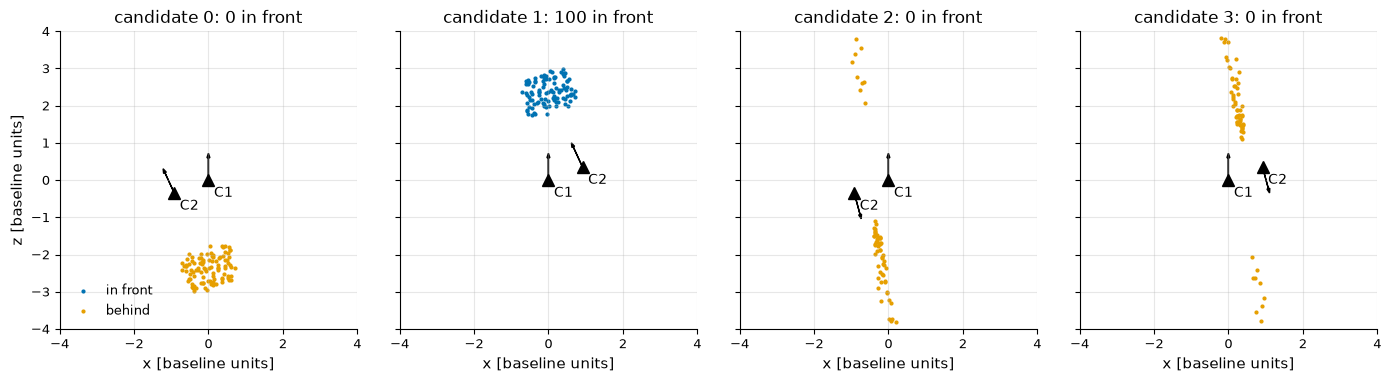

In [8]:
# --- Visualise the four configurations (top view, camera-1 frame: x right, z forward) ---
# Points with positive depth in both cameras are blue, the others orange.
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharex=True, sharey=True)
for k, ax in enumerate(axes):
    R_c, t_c = cands[k]
    X_c = tri[k]
    z2 = (X_c @ R_c.T + t_c)[:, 2]
    ok = (X_c[:, 2] > 0) & (z2 > 0)
    C2 = -R_c.T @ t_c  # camera-2 centre in camera-1 coordinates (unit baseline)
    ax.scatter(X_c[ok, 0], X_c[ok, 2], s=4, color=viz.color(0, unit=True), label="in front")
    ax.scatter(X_c[~ok, 0], X_c[~ok, 2], s=4, color=viz.color(1, unit=True), label="behind")
    for C, R_wc, name in [(np.zeros(3), np.eye(3), "C1"), (C2, R_c.T, "C2")]:
        ax.plot(C[0], C[2], "k^", ms=8)
        fwd = R_wc[:, 2] * 0.6  # optical axis direction
        ax.arrow(C[0], C[2], fwd[0], fwd[2], head_width=0.08, color="k")
        ax.annotate(name, (C[0], C[2]), textcoords="offset points", xytext=(4, -12))
    ax.set_title(f"candidate {k}: {rows[k]['in front of both']} in front")
    ax.set_xlabel("x [baseline units]")
    ax.set_xlim(-4, 4)
    ax.set_ylim(-4, 4)
    ax.set_aspect("equal")
axes[0].set_ylabel("z [baseline units]")
axes[0].legend(loc="lower left")
plt.show()

## 5. Triangulation

Given $P_1 = K[I|0]$ and $P_2 = K[R|t]$, each view gives $x_i \times (P_i X) = 0$, i.e. two
independent linear equations in the homogeneous point $X$:

$$\begin{bmatrix} u_1 p_1^{3\top} - p_1^{1\top} \\ v_1 p_1^{3\top} - p_1^{2\top} \\
u_2 p_2^{3\top} - p_2^{1\top} \\ v_2 p_2^{3\top} - p_2^{2\top}\end{bmatrix} X = 0 ,$$

solved by SVD (**DLT**). DLT minimises an algebraic error; the statistically optimal
estimate under Gaussian pixel noise minimises the **reprojection error**
$\sum_i \lVert x_i - \pi(P_i X)\rVert^2$. A close approximation is to first move both points
onto a consistent pair of epipolar lines (`cv2.correctMatches`, Hartley–Sturm) and then
triangulate.

We compare our DLT (`cvlab.geometry.triangulate_dlt`), `cv2.triangulatePoints` and
"correctMatches + DLT" on noisy versions of the ground-truth correspondences.

In [9]:
# --- Triangulation accuracy vs pixel noise (metric relative pose known) ---
P1 = M.projection_matrix(K, np.eye(3), np.zeros(3))
P2 = M.projection_matrix(K, R_gt, t_gt)
X_cam1 = G.transform_points(G.invert_T(T_wc1), X_vis)  # ground truth in the camera-1 frame

def reproj_err(X, a, b):
    e1 = np.linalg.norm(G.project(X, K)[0] - a, axis=1)
    e2 = np.linalg.norm(G.project(X @ R_gt.T + t_gt, K)[0] - b, axis=1)
    return 0.5 * (e1 + e2)

tri_rows = []
for s in [0.25, 0.5, 1.0, 2.0]:
    rng_s = np.random.default_rng(42)
    a = x1_all + rng_s.normal(0, s, x1_all.shape)
    b = x2_all + rng_s.normal(0, s, x2_all.shape)
    t0 = time.perf_counter()
    X_dlt = G.triangulate_dlt(P1, P2, a, b)
    t_dlt = time.perf_counter() - t0
    t0 = time.perf_counter()
    Xh = cv2.triangulatePoints(P1, P2, a.T, b.T)
    X_cv = (Xh[:3] / Xh[3]).T
    t_cv = time.perf_counter() - t0
    a_c, b_c = cv2.correctMatches(F_gt, a[None], b[None])
    X_opt = G.triangulate_dlt(P1, P2, a_c[0], b_c[0])
    for name, X, dt in [("DLT (cvlab)", X_dlt, t_dlt), ("cv2.triangulatePoints", X_cv, t_cv),
                        ("correctMatches + DLT", X_opt, None)]:
        tri_rows.append({"sigma_px": s, "method": name,
                         "rmse_3d_mm": 1000 * np.sqrt(np.mean(np.sum((X - X_cam1) ** 2, 1))),
                         "reproj_err_px": reproj_err(X, a, b).mean(),
                         "time_ms": None if dt is None else 1000 * dt})
tri_df = pd.DataFrame(tri_rows)
ang = M.triangulation_angle_deg(X_vis, T_wc1[:3, 3], T_wc2[:3, 3])
print(f"median triangulation angle of the GT pair: {np.median(ang):.1f} deg")
tri_df.round(3)

median triangulation angle of the GT pair: 23.7 deg


,sigma_px,method,rmse_3d_mm,reproj_err_px,time_ms
0,0.25,DLT (cvlab),5.351,0.145,5.323
1,0.25,cv2.triangulatePoints,5.351,0.145,0.209
2,0.25,correctMatches + DLT,5.352,0.144,NaN
3,0.50,DLT (cvlab),10.704,0.290,4.195
4,0.50,cv2.triangulatePoints,10.704,0.290,0.197
5,0.50,correctMatches + DLT,10.704,0.289,NaN
6,1.00,DLT (cvlab),21.413,0.580,4.167
7,1.00,cv2.triangulatePoints,21.413,0.580,0.194
8,1.00,correctMatches + DLT,21.414,0.577,NaN
9,2.00,DLT (cvlab),42.861,1.161,4.187


All three give the same 3D accuracy here: with this wide baseline (the median
triangulation angle is printed above) the linear solution is already close to optimal.
"correctMatches + DLT" reaches the lowest reprojection error, as expected from the
method that minimises it, yet the 3D error does not improve: reprojection error measures
consistency with the noisy data, not distance to the truth. `cv2.triangulatePoints`
(vectorised C++) is much faster than our per-point Python loop.

**Baseline matters.** For a rectified stereo pair, $Z = fB/d$, so a disparity error
$\sigma_d$ becomes a depth error

$$\sigma_Z \approx \frac{Z^2}{f\,B}\,\sigma_d ,$$

which grows with the square of distance and inversely with the baseline $B$. Below,
camera 2 slides along camera 1's x-axis (always looking at the same target), and we
measure the median absolute depth error for 0.5 px noise per image. Two independent
0.5 px errors give $\sigma_d = \sqrt{2}\cdot 0.5$ px, and the median of $|\mathcal{N}(0,\sigma_Z)|$
is $0.674\,\sigma_Z$; that is the prediction column.

In [10]:
# --- Depth error vs baseline: the parallax / accuracy trade-off ---
# For each baseline we triangulate noisy correspondences with the true relative pose.
sigma = 0.5
baselines = [0.02, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0]  # metres
base_rows = []
x_axis = T_wc1[:3, 0]  # camera-1 x axis in the world frame
for B in baselines:
    T_b = G.look_at(eye=T_wc1[:3, 3] + B * x_axis, target=[0.0, 0.2, 0.7])
    R_b, t_b = M.relative_pose_from_c2w(T_wc1, T_b)
    uv_a, za = G.project_points(X_world, K, G.invert_T(T_wc1))
    uv_b, zb = G.project_points(X_world, K, G.invert_T(T_b))
    ok = (za > 0) & (zb > 0) & cam.in_image(uv_a) & cam.in_image(uv_b)
    rng_b = np.random.default_rng(7)
    a = uv_a[ok] + rng_b.normal(0, sigma, (ok.sum(), 2))
    b = uv_b[ok] + rng_b.normal(0, sigma, (ok.sum(), 2))
    X = G.triangulate_dlt(P1, M.projection_matrix(K, R_b, t_b), a, b)
    Z_true = G.transform_points(G.invert_T(T_wc1), X_world[ok])[:, 2]
    angle = M.triangulation_angle_deg(X_world[ok], T_wc1[:3, 3], T_b[:3, 3])
    base_rows.append({"baseline_m": B, "median_tri_angle_deg": np.median(angle),
                      "median_abs_depth_err_m": np.median(np.abs(X[:, 2] - Z_true)),
                      "predicted_median_err_m": 0.6745 * np.median(Z_true) ** 2 / (cam.fx * B) * np.sqrt(2) * sigma})
base_df = pd.DataFrame(base_rows)
base_df.round(4)

,baseline_m,median_tri_angle_deg,median_abs_depth_err_m,predicted_median_err_m
0,0.02,0.3218,0.4756,0.5003
1,0.05,0.8051,0.1975,0.2001
2,0.10,1.6119,0.0988,0.1001
3,0.20,3.2241,0.0493,0.0500
4,0.50,8.0451,0.0203,0.0200
5,1.00,15.8324,0.0104,0.0100
6,2.00,29.4778,0.0059,0.0050


## 6. Real images: TUM RGB-D `fr1_desk` with motion-capture ground truth

The TUM sequence provides calibrated intrinsics and lens distortion for the Kinect RGB
camera and camera poses from a motion-capture system. For pairs of frames $(i, i+g)$ with a
gap of $g \in \{5, 10, 20\}$ frames (30 Hz), we:

1. detect SIFT features and match them (ratio test 0.8 + mutual nearest neighbour),
2. undistort the matched pixel coordinates (`cv2.undistortPoints`, so the pinhole model holds),
3. estimate the relative pose with three methods and compare against the ground truth
   $R_{gt}, t_{gt}$ from the mocap poses.

Pairs whose ground-truth baseline is below 2 cm are skipped: the translation *direction*
is ill-defined for nearly zero translation. The summary metric is the **pose AUC**: for
each pair, take $\max(\text{rot err}, \text{t-direction err})$, build the cumulative curve,
and report its normalised area up to 5°, 10° and 20° (as in SuperGlue / LoFTR / LightGlue).

In [11]:
# --- Relative pose on real image pairs: 8-pt vs 8-pt+RANSAC vs 5-pt+RANSAC ---
# SIFT runs on the CPU (OpenCV); pixel coordinates are undistorted before any estimation.
seq = load_sequence(data_dir("tum", "fr1_desk", "rgbd_dataset_freiburg1_desk"))
K_t, dist_t = seq.camera.K, seq.dist
print(f"TUM fr1_desk: {len(seq)} frames, K =\n{K_t}\ndistortion k1,k2,p1,p2,k3 = {dist_t}")

def undistort_px(x):
    return cv2.undistortPoints(x.reshape(-1, 1, 2), K_t, dist_t, P=K_t).reshape(-1, 2)

def estimate(name, a, b):
    if name == "8-pt (all matches)":
        F = M.eight_point(a, b)
        E = M.essential_from_fundamental(F, K_t, K_t)
        _, R, t, _ = cv2.recoverPose(E, a, b, K_t)
    elif name == "8-pt + RANSAC":
        F, mask = cv2.findFundamentalMat(a, b, cv2.FM_RANSAC, 1.0, 0.999)
        E = M.essential_from_fundamental(F[:3], K_t, K_t)
        _, R, t, _ = cv2.recoverPose(E, a, b, K_t, mask=mask.copy())
    else:
        method = cv2.RANSAC if name == "5-pt + RANSAC" else cv2.USAC_MAGSAC
        E, mask = cv2.findEssentialMat(a, b, K_t, method, 0.999, 1.0)
        _, R, t, _ = cv2.recoverPose(E[:3], a, b, K_t, mask=mask.copy())
    return R, t.ravel()

REAL_METHODS = ["8-pt (all matches)", "8-pt + RANSAC", "5-pt + RANSAC", "5-pt + MAGSAC++"]
real_rows, cache = [], {}
t0 = time.perf_counter()
for gap in (5, 10, 20):
    for i in range(0, len(seq) - gap, 30):
        j = i + gap
        R_rel, t_rel = M.relative_pose_from_c2w(seq.gt_poses[i], seq.gt_poses[j])
        if np.linalg.norm(t_rel) < 0.02:
            continue
        m = M.sift_match(seq.rgb(i), seq.rgb(j))
        a, b = undistort_px(m.x1), undistort_px(m.x2)
        cache[(i, j)] = (a, b)
        for name in REAL_METHODS:
            er, et = M.pose_errors(*estimate(name, a, b), R_rel, t_rel)
            real_rows.append({"gap": gap, "i": i, "method": name, "n_matches": len(m),
                              "baseline_m": np.linalg.norm(t_rel), "rot_err_deg": er,
                              "t_err_deg": et, "max_err_deg": max(er, et)})
real_df = pd.DataFrame(real_rows)
print(f"{real_df[['gap', 'i']].drop_duplicates().shape[0]} pairs evaluated in "
      f"{time.perf_counter() - t0:.1f} s")
auc_rows = []
for name in REAL_METHODS:
    d = real_df[real_df.method == name]
    auc_rows.append({"method": name, **M.pose_auc(d.max_err_deg.values),
                     "median rot err [deg]": d.rot_err_deg.median(),
                     "median t err [deg]": d.t_err_deg.median()})
real_auc = pd.DataFrame(auc_rows)
real_auc.round(3)

TUM fr1_desk: 573 frames, K =
[[517.3   0.  318.6]
 [  0.  516.5 255.3]
 [  0.    0.    1. ]]
distortion k1,k2,p1,p2,k3 = [ 0.2624 -0.9531 -0.0054  0.0026  1.1633]


56 pairs evaluated in 5.9 s


,method,auc@5,auc@10,auc@20,median rot err [deg],median t err [deg]
0,8-pt (all matches),0.000,0.000,0.012,7.725,65.308
1,8-pt + RANSAC,0.069,0.174,0.283,2.085,27.232
2,5-pt + RANSAC,0.143,0.339,0.554,1.213,6.717
3,5-pt + MAGSAC++,0.270,0.480,0.662,0.875,5.336


The plain 8-point algorithm uses every putative match, including the mismatches that
survive the ratio test, so a handful of outliers ruins most pairs. Inside RANSAC the
solvers do far better, and the calibrated 5-point solver beats 8-point RANSAC: it uses the
known $K$, needs smaller samples, and is not degenerate when all points lie on one plane
(the desk top dominates many frames), whereas $F$ is not uniquely defined for a planar
scene. MAGSAC++ with its final refinement is the most accurate.

Finally, the epipolar lines of the MAGSAC++ estimate on one real pair (the 20-frame pair
with the most matches), drawn on the undistorted images (lines are only straight after
undistortion).

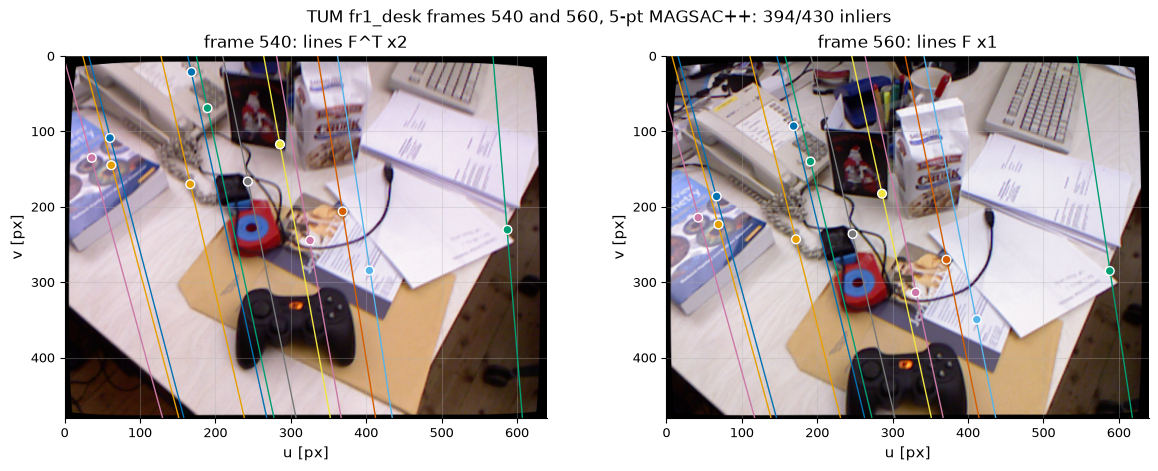

In [12]:
# --- Epipolar lines on a real pair (5-pt MAGSAC++ estimate, undistorted images) ---
# Show the gap-20 pair with the most SIFT matches (many fr1_desk frames are motion-blurred).
i, j = max((k for k in cache if k[1] - k[0] == 20), key=lambda k: len(cache[k][0]))
a, b = cache[(i, j)]
E, mask = cv2.findEssentialMat(a, b, K_t, cv2.USAC_MAGSAC, 0.999, 1.0)
F_est = np.linalg.inv(K_t).T @ E[:3] @ np.linalg.inv(K_t)
inl = np.flatnonzero(mask.ravel())
sel = np.random.default_rng(3).choice(inl, 12, replace=False)
img1 = cv2.undistort(seq.rgb(i), K_t, dist_t)
img2 = cv2.undistort(seq.rgb(j), K_t, dist_t)
cols = [viz.color(k, unit=True) for k in range(len(sel))]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, img, pts, lines, title in [
        (axes[0], img1, a, M.to_h(b[sel]) @ F_est, f"frame {i}: lines F^T x2"),
        (axes[1], img2, b, M.to_h(a[sel]) @ F_est.T, f"frame {j}: lines F x1")]:
    ax.imshow(img)
    ax.scatter(pts[sel, 0], pts[sel, 1], s=40, c=cols, edgecolors="w", zorder=3)
    draw_lines(ax, lines, cols, img.shape[1])
    ax.set_xlim(0, img.shape[1])
    ax.set_ylim(img.shape[0], 0)
    ax.set_xlabel("u [px]")
    ax.set_ylabel("v [px]")
    ax.set_title(title)
fig.suptitle(f"TUM fr1_desk frames {i} and {j}, 5-pt MAGSAC++: {len(inl)}/{len(a)} inliers")
viz.savefig(fig, PROJECT, "epipolar_lines_tum")
plt.show()

## Results

All numbers below were measured in this notebook (synthetic scene: median over 50 trials of
100 correspondences; real data: SIFT matches on TUM `fr1_desk`).

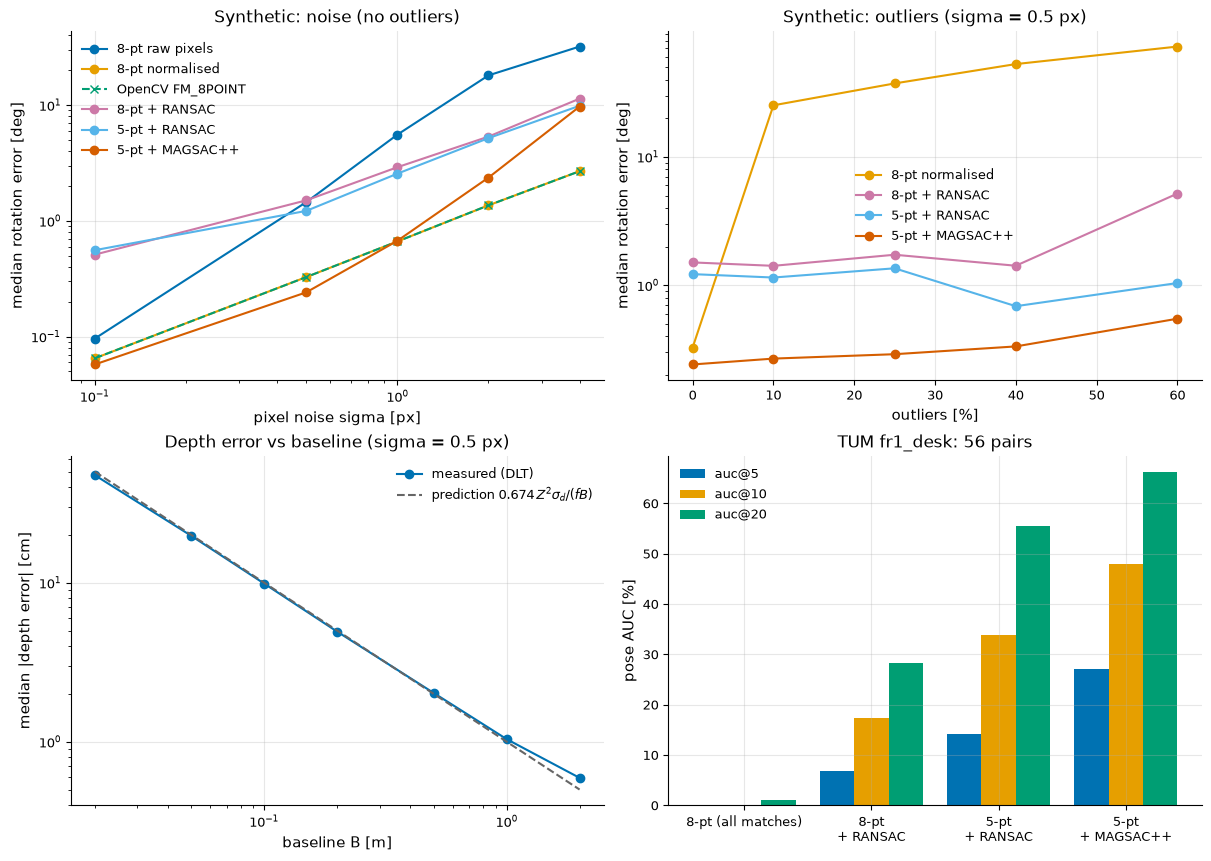

In [13]:
# --- Summary figure: noise, outliers, baseline and real-data AUC ---
fig, ax = plt.subplots(2, 2, figsize=(12, 8.5))
COLOR = {name: viz.color(k, unit=True) for k, name in enumerate(METHODS)}  # same in both plots
for name in METHODS:
    d = noise_df[noise_df.method == name]
    style = "x--" if name.startswith("OpenCV") else "o-"  # overlaps "8-pt normalised" exactly
    ax[0, 0].plot(d.sigma_px, d.rot_err_deg, style, label=name, color=COLOR[name])
ax[0, 0].set(xscale="log", yscale="log", xlabel="pixel noise sigma [px]",
             ylabel="median rotation error [deg]", title="Synthetic: noise (no outliers)")
ax[0, 0].legend()
for name in ROBUST:
    d = outlier_df[outlier_df.method == name]
    ax[0, 1].plot(100 * d.outlier_frac, d.rot_err_deg, "o-", label=name, color=COLOR[name])
ax[0, 1].set(yscale="log", xlabel="outliers [%]", ylabel="median rotation error [deg]",
             title="Synthetic: outliers (sigma = 0.5 px)")
ax[0, 1].legend()
ax[1, 0].loglog(base_df.baseline_m, 100 * base_df.median_abs_depth_err_m, "o-",
                label="measured (DLT)", color=viz.color(0, unit=True))
ax[1, 0].loglog(base_df.baseline_m, 100 * base_df.predicted_median_err_m, "--",
                label=r"prediction $0.674\,Z^2\sigma_d/(fB)$", color="0.4")
ax[1, 0].set(xlabel="baseline B [m]", ylabel="median |depth error| [cm]",
             title="Depth error vs baseline (sigma = 0.5 px)")
ax[1, 0].legend()
xs = np.arange(len(REAL_METHODS))
for k, thr in enumerate(["auc@5", "auc@10", "auc@20"]):
    ax[1, 1].bar(xs + (k - 1) * 0.27, 100 * real_auc[thr], width=0.27, label=thr,
                 color=viz.color(k, unit=True))
ax[1, 1].set_xticks(xs, [n.replace(" + ", "\n+ ") for n in real_auc.method])
ax[1, 1].set(ylabel="pose AUC [%]", title=f"TUM fr1_desk: {real_df[['gap', 'i']].drop_duplicates().shape[0]} pairs")
ax[1, 1].legend()
viz.savefig(fig, PROJECT, "two_view_summary")
plt.show()

The summary table collects the headline numbers: rotation and translation-direction error at
1 px of noise for every estimator, the rotation error of the robust ones with 25 % outliers,
and the pose AUC on the real TUM pairs.

In [14]:
# --- Summary table of the measured numbers (also saved to results/nb01_two_view.json) ---
pick = lambda df, col, val, name, m: float(df[(df[col] == val) & (df.method == name)][m].iloc[0])  # noqa: E731
summary = []
for name in METHODS:
    row = {"method": name,
           "rot err @1px [deg]": pick(noise_df, "sigma_px", 1.0, name, "rot_err_deg"),
           "t-dir err @1px [deg]": pick(noise_df, "sigma_px", 1.0, name, "t_err_deg")}
    if name in ROBUST:
        row["rot err @25% outliers [deg]"] = pick(outlier_df, "outlier_frac", 0.25, name, "rot_err_deg")
    summary.append(row)
summary_df = pd.DataFrame(summary)
save_json({"noise": noise_rows, "outliers": out_rows, "triangulation": tri_rows,
           "baseline": base_rows, "tum_auc": auc_rows, "summary": summary},
          RESULTS_DIR / "nb01_two_view.json")
display(summary_df.round(3))
display(real_auc.round(3))

,method,rot err @1px [deg],t-dir err @1px [deg],rot err @25% outliers [deg]
0,8-pt raw pixels,5.563,9.221,NaN
1,8-pt normalised,0.664,1.344,37.323
2,OpenCV FM_8POINT,0.664,1.344,NaN
3,8-pt + RANSAC,2.909,4.899,1.728
4,5-pt + RANSAC,2.560,2.458,1.355
5,5-pt + MAGSAC++,0.673,0.772,0.290


,method,auc@5,auc@10,auc@20,median rot err [deg],median t err [deg]
0,8-pt (all matches),0.000,0.000,0.012,7.725,65.308
1,8-pt + RANSAC,0.069,0.174,0.283,2.085,27.232
2,5-pt + RANSAC,0.143,0.339,0.554,1.213,6.717
3,5-pt + MAGSAC++,0.270,0.480,0.662,0.875,5.336


**Takeaways**

* The epipolar constraint holds to machine precision on noise-free data; $E$ has singular
  values $(1, 1, 0)$ and the epipoles are the images of the other camera centre.
* **Normalise before the 8-point algorithm.** Our Hartley-normalised implementation matches
  OpenCV's `FM_8POINT` and is far more accurate than the raw-pixel version (table above).
* **Refine after RANSAC.** Classic RANSAC returns a minimal-sample model; without outliers it
  is several times less accurate than least squares. MAGSAC++ (local optimisation + final
  inlier fit) is the most accurate *robust* estimator in every setting here, and matches
  least squares on clean data up to about 1 px of noise (not beyond).
* Least squares has no defence against outliers: with 25 % mismatches the plain 8-point pose
  is unusable while all RANSAC variants stay accurate. At 60 % outliers the 8-point RANSAC
  (sample size 8, default 1000 iterations) degrades first, because outlier-free 8-samples
  become rare.
* `recoverPose`'s cheirality test is what turns the four-fold ambiguity of $E$ into one pose:
  exactly one candidate puts the points in front of both cameras.
* Depth error grows as $1/B$ (and as $Z^2$): small-baseline stereo or VO keyframes that are
  too close together give noisy depth. The measured median error tracks the
  $0.674\,Z^2\sigma_d/(fB)$ prediction to within about 20 % (the cameras also
  rotate to keep the target in view, so this is not an exactly rectified rig).
* On real TUM images the robust estimators win clearly and the plain 8-point fails; the
  translation direction is the weakest quantity (baselines of a few cm, motion blur, rolling
  shutter and mocap-to-camera synchronisation all limit it), so the AUC values stay modest.

## Exercises

Solutions: `projects/09_multiview_geometry/solutions/solutions_01.py`.

**Exercise 1: RANSAC around your own 8-point solver.** Write `ransac_eight_point(a, b,
thr_px, iters)` that repeatedly fits `M.eight_point` on 8 random correspondences, scores it
with the Sampson distance (`M.sampson_distance`, in px²) and refits on the inliers of the
best model. Compare its inlier count and pose error with `cv2.findFundamentalMat(...,
cv2.FM_RANSAC)` on the 25 % outlier setting.

In [15]:
# --- Exercise 1: RANSAC + 8-point (TODO) ---
def ransac_eight_point(a, b, thr_px=1.5, iters=2000, seed=0):
    # TODO: sample 8 indices, fit M.eight_point, count inliers with
    #       M.sampson_distance(F, a, b) < thr_px**2, keep the best, refit on its inliers.
    raise NotImplementedError

# a, b = sample(100, 0.5, 0.25, np.random.default_rng(0))
# F, inliers = ransac_eight_point(a, b)

**Exercise 2: the pure-rotation degeneracy.** Put camera 2 at the *same* centre as camera 1
(rotated by a few degrees, $t = 0$). Show that `cv2.findEssentialMat` + `recoverPose` still
return *some* translation (which is meaningless), and that a homography
$H = K R K^{-1}$ (`cv2.findHomography`) explains all correspondences with sub-pixel error.
Why does this matter for initialising monocular SLAM / SfM?

In [16]:
# --- Exercise 2: pure rotation, E is undefined but a homography fits (TODO) ---
# TODO: T_wc_rot = G.make_T(T_wc1[:3, :3] @ G.so3_exp(np.deg2rad([2, 5, 1])), T_wc1[:3, 3])
#       project X_world into both views, add 0.5 px noise, estimate E and H, compare.

**Exercise 3: epipoles and the camera centres.** Using the *estimated* $F$ from the 5-point
MAGSAC++ solver on the real TUM pair shown above (`i`, `j`), compute the epipoles from the null spaces
of $F$ and $F^\top$, and compare $e_2$ with the projection of camera $i$'s mocap position into
frame $j$. Explain the size of the discrepancy.

In [17]:
# --- Exercise 3: epipoles from F vs projected camera centres (TODO) ---
# TODO: e1 = null(F), e2 = null(F^T); project seq.gt_poses[i][:3, 3] with T_cw of frame j.